# Módulo 04 

Notebook 2: *Baseline* y primeros modelos para House Prices

**Pregunta de negocio (módulo 02):** ¿podemos dar un avalúo automático con un error típico (MAPE) **menor al 15 %**?

**Plan**
1. Dividir los datos en **train / validación / test**.
2. Construir un ***baseline*** (el modelo "tonto" que hay que superar).
3. Probar modelos de complejidad creciente y vigilar el *overfitting*.
4. Validación cruzada, importancia de variables y análisis de errores.
5. Evaluar **una sola vez** en test.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor

from intro_analitica import config
from intro_analitica.datos import cargar_house_prices_limpio
from intro_analitica.metricas import brecha_overfitting, metricas_regresion, tabla_comparativa

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

df = cargar_house_prices_limpio()
print(df.shape)

(1452, 86)


## 1. Variables del modelo

Usamos las variables que el EDA (módulo 03) señaló como importantes. Están definidas en `config.py` porque **la API del módulo 05 pedirá exactamente estas mismas**.

In [3]:
NUMERICAS = config.FEATURES_NUMERICAS
CATEGORICAS = config.FEATURES_CATEGORICAS
print("Numéricas  :", NUMERICAS)
print("Categóricas:", CATEGORICAS)

X = df[NUMERICAS + CATEGORICAS]
y = df[config.TARGET]

Numéricas  : ['LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'GrLivArea', 'TotalBsmtSF', 'FullBath', 'BedroomAbvGr', 'GarageCars']
Categóricas: ['Neighborhood', 'BldgType', 'HouseStyle', 'KitchenQual']


## 2. Train / validación / test

```
 ┌──────────────────────── 100 % de los datos ───────────────────────┐
 │        TRAIN (60 %)            │  VALIDACIÓN (20 %) │  TEST (20 %) │
 │  el modelo aprende aquí        │  elegimos modelo   │  se usa   │
 │                                │  e hiperparámetros │  UNA vez     │
 └────────────────────────────────┴────────────────────┴──────────────┘
```

**¿Por qué tres conjuntos?** Si eliges el modelo mirando el test, el test deja de ser "datos nuevos": terminas ajustándote a él sin darte cuenta.

In [4]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=config.SEMILLA)
X_train, X_valid, y_train, y_valid = train_test_split(X_temp, y_temp, test_size=0.25, random_state=config.SEMILLA)
print(f"Train: {len(X_train)} · Validación: {len(X_valid)} · Test: {len(X_test)}")

Train: 870 · Validación: 291 · Test: 291


### Preprocesamiento manual (y por qué el módulo 05 existe)

Los modelos necesitan números, así que codificamos las categóricas con one-hot. **Ajustamos el encoder solo con train** para evitar *data leakage*.
`handle_unknown="ignore"` evita un error si en validación o test aparece una categoría que no estaba en train.

In [5]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[CATEGORICAS])


def preparar(X_parte: pd.DataFrame) -> pd.DataFrame:
    """Numéricas tal cual + categóricas en one-hot (con el encoder ajustado en train)."""
    dummies = pd.DataFrame(
        encoder.transform(X_parte[CATEGORICAS]),
        columns=encoder.get_feature_names_out(CATEGORICAS),
        index=X_parte.index,
    )
    return pd.concat([X_parte[NUMERICAS], dummies], axis=1)


Xtr, Xva, Xte = preparar(X_train), preparar(X_valid), preparar(X_test)
print("Columnas después del one-hot:", Xtr.shape[1])

Columnas después del one-hot: 52


> Tener que acordarse de `fit` en train, `transform` en todo, guardar el encoder… es fácil equivocarse. En el **módulo 05** un `Pipeline` hará todo esto por nosotros.

---
## 3. El *baseline*: el modelo a superar

El *baseline* más simple: **predecir siempre la mediana** del train. Si un modelo "inteligente" no le gana a esto, no sirve.

In [6]:
resultados = {}  # {nombre: métricas en validación}
entrenamiento = {}  # {nombre: métricas en train}


def evaluar(nombre, modelo, X_tr=Xtr, X_va=Xva, y_tr=y_train, transformar_y=None):
    """Entrena, calcula métricas en train y validación y las guarda."""
    if transformar_y == "log":
        modelo.fit(X_tr, np.log1p(y_tr))
        pred_tr, pred_va = np.expm1(modelo.predict(X_tr)), np.expm1(modelo.predict(X_va))
    else:
        modelo.fit(X_tr, y_tr)
        pred_tr, pred_va = modelo.predict(X_tr), modelo.predict(X_va)
    entrenamiento[nombre] = metricas_regresion(y_tr, pred_tr)
    resultados[nombre] = metricas_regresion(y_valid, pred_va)
    return modelo


evaluar("0. Baseline (mediana)", DummyRegressor(strategy="median"))
pd.DataFrame(resultados).T

,MAE,RMSE,MAPE_%,R2
0. Baseline (mediana),"55,746.59","87,893.86",30.60,-0.05


El *baseline* se equivoca en promedio un **~31 %** (MAPE). Ese es el número a vencer.

---
## 4. Modelos de complejidad creciente

### 4.1 Regresión lineal

In [7]:
evaluar("1. Lineal (solo numéricas)", LinearRegression(), X_tr=Xtr[NUMERICAS], X_va=Xva[NUMERICAS])
lineal = evaluar("2. Lineal (+ categóricas)", LinearRegression())
evaluar("3. Lineal + log(target)", LinearRegression(), transformar_y="log")
tabla_comparativa(resultados)

,MAE,RMSE,MAPE_%,R2
3. Lineal + log(target),"19,754.49","29,305.83",11.00,0.88
2. Lineal (+ categóricas),"20,682.88","34,971.56",11.25,0.83
1. Lineal (solo numéricas),"22,904.33","37,096.80",12.46,0.81
0. Baseline (mediana),"55,746.59","87,893.86",30.60,-0.05


**Lectura:**
- La regresión lineal ya deja el MAPE en **menos de la mitad** que el *baseline* (~12 % frente a ~31 %).
- Agregar las categóricas (barrio, calidad de la cocina…) ayuda.
- Usar **log(precio)** (hallazgo #1 del EDA) mejora aún más: el modelo deja de "pelear" con la cola de casas caras.

### 4.2 Árbol de decisión y el *overfitting* en vivo

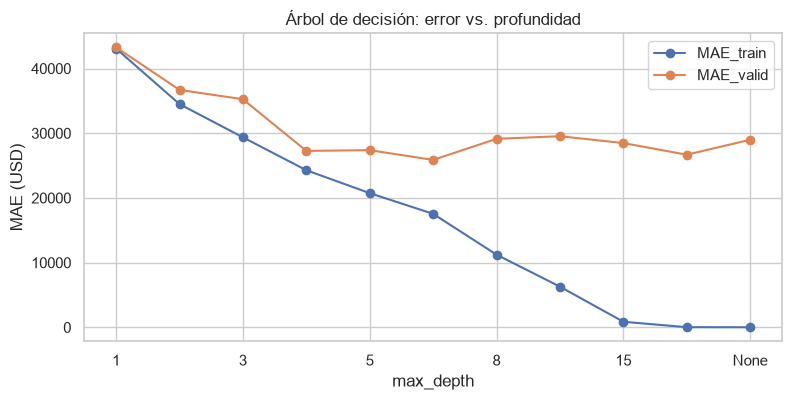

max_depth,1,2,3,4,5,6,8,10,15,20,None
MAE_train,"43,082.90","34,498.68","29,365.20","24,279.70","20,739.70","17,540.99","11,234.50","6,286.20",863.43,26.07,12.58
MAE_valid,"43,281.31","36,695.06","35,252.46","27,265.64","27,381.25","25,874.41","29,134.93","29,537.85","28,479.29","26,680.31","28,987.51"


In [8]:
profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None]
curva = []
for prof in profundidades:
    arbol = DecisionTreeRegressor(max_depth=prof, random_state=config.SEMILLA).fit(Xtr, y_train)
    curva.append(
        {
            "max_depth": str(prof),
            "MAE_train": metricas_regresion(y_train, arbol.predict(Xtr))["MAE"],
            "MAE_valid": metricas_regresion(y_valid, arbol.predict(Xva))["MAE"],
        }
    )
curva = pd.DataFrame(curva).set_index("max_depth")

ax = curva.plot(marker="o", figsize=(9, 4))
ax.set(title="Árbol de decisión: error vs. profundidad", ylabel="MAE (USD)")
plt.show()
curva.T

Con `max_depth=None` el árbol **memoriza** el train (MAE de train ≈ 0), pero en validación se equivoca en promedio por casi USD 30.000: ***overfitting*** de libro.
La mejor profundidad está en el "valle" de la curva de validación.

In [9]:
mejor_prof = int(curva["MAE_valid"].drop("None").idxmin())
print("Mejor profundidad en validación:", mejor_prof)
evaluar(f"4. Árbol (max_depth={mejor_prof})", DecisionTreeRegressor(max_depth=mejor_prof, random_state=config.SEMILLA))

Mejor profundidad en validación: 6


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [10]:
curva

,MAE_train,MAE_valid
max_depth,,
1,"43,082.90","43,281.31"
2,"34,498.68","36,695.06"
3,"29,365.20","35,252.46"
4,"24,279.70","27,265.64"
5,"20,739.70","27,381.25"
6,"17,540.99","25,874.41"
8,"11,234.50","29,134.93"
10,"6,286.20","29,537.85"
15,863.43,"28,479.29"


### 4.3 *Ensembles*: muchos árboles juntos

| Modelo | Idea |
|---|---|
| **Random Forest** | Cientos de árboles entrenados con muestras distintas; se **promedian** sus predicciones (reduce la varianza) |
| **Gradient Boosting** | Árboles en **secuencia**: cada uno corrige los errores del anterior (reduce el sesgo) |


### ¿Qué es la varianza de un modelo?

- Varianza alta: si se cambian unas pocas casas del entrenamiento, el modelo cambia mucho y predice cosas muy distintas. Es un modelo inestable.

- Varianza baja: aunque cambien los datos, el modelo predice más o menos lo mismo. Es un modelo estable.

In [11]:
bosque = evaluar("5. Random Forest", RandomForestRegressor(n_estimators=300, random_state=config.SEMILLA, n_jobs=-1))
evaluar("6. Gradient Boosting", HistGradientBoostingRegressor(random_state=config.SEMILLA))
evaluar("7. Gradient Boosting + log", HistGradientBoostingRegressor(random_state=config.SEMILLA), transformar_y="log")

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [12]:
try:
    from xgboost import XGBRegressor

    evaluar(
        "8. XGBoost + log",
        XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=4, subsample=0.8, random_state=config.SEMILLA),
        transformar_y="log",
    )
except ImportError:
    print("XGBoost no está instalado (uv sync lo instala). Seguimos sin él.")

---
## 5. La tabla comparativa

In [13]:
comparacion = tabla_comparativa(resultados)
comparacion["MAE_train"] = [entrenamiento[m]["MAE"] for m in comparacion.index]
comparacion["brecha_%"] = [brecha_overfitting(entrenamiento[m]["MAE"], resultados[m]["MAE"]) for m in comparacion.index]
comparacion

,MAE,RMSE,MAPE_%,R2,MAE_train,brecha_%
3. Lineal + log(target),"19,754.49","29,305.83",11.00,0.88,"18,302.59",7.90
2. Lineal (+ categóricas),"20,682.88","34,971.56",11.25,0.83,"19,263.09",7.40
8. XGBoost + log,"18,652.69","35,444.88",9.91,0.83,"4,786.24",289.70
5. Random Forest,"19,352.91","36,294.16",10.27,0.82,"6,797.50",184.70
1. Lineal (solo numéricas),"22,904.33","37,096.80",12.46,0.81,"23,749.57",-3.60
6. Gradient Boosting,"20,538.29","37,266.11",10.96,0.81,"7,743.40",165.20
4. Árbol (max_depth=6),"25,874.41","38,089.96",14.81,0.80,"17,540.99",47.50
7. Gradient Boosting + log,"19,657.96","38,398.98",10.23,0.80,"7,449.91",163.90
0. Baseline (mediana),"55,746.59","87,893.86",30.60,-0.05,"55,394.91",0.60


**Cómo leer la tabla:**
- **MAPE**: ¿cumplimos el criterio de negocio (< 15 %)?
- **brecha_%**: cuánto peor le va en validación que en train. Los *ensembles* (Random Forest, Gradient Boosting) tienen brechas enormes: casi memorizan el train. Aun así, su error en validación es de los mejores. **Lo que importa es el error en datos nuevos**; la brecha es una alerta para regularizar.
- Los *ensembles* y la **lineal con log** quedan muy cerca: todos alrededor del 10-11 % de MAPE, **muy por debajo del criterio de 15 %**.

> **Desempeño vs. interpretabilidad:** si la regresión lineal está muy cerca del mejor modelo, puede valer la pena elegirla porque **se explica** fácilmente ("cada m² suma X dólares").

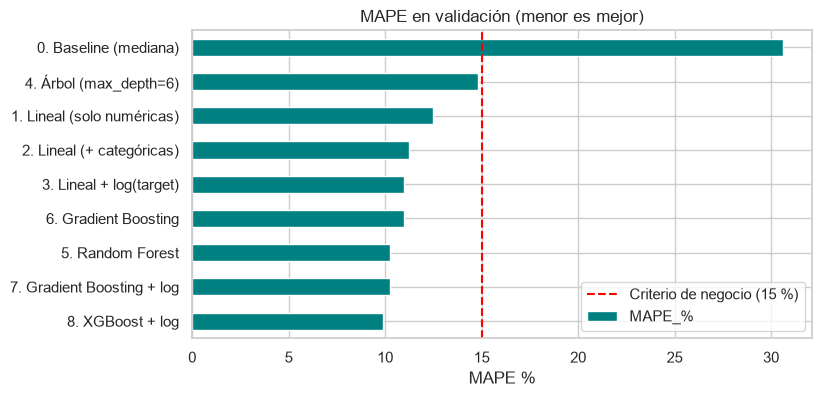

In [14]:
ax = comparacion["MAPE_%"].sort_values().plot(kind="barh", figsize=(8, 4), color="teal")
ax.axvline(15, color="red", ls="--", label="Criterio de negocio (15 %)")
ax.set(title="MAPE en validación (menor es mejor)", xlabel="MAPE %")
ax.legend()
plt.show()

---
## 6. Validación cruzada: ¿y si tuvimos suerte con el split?

Un solo split de validación puede salir "fácil" o "difícil" por azar. La **validación cruzada (k-fold)** entrena y evalúa k veces, con un pedazo distinto como validación cada vez.

```
 Fold 1: [VAL][ tr ][ tr ][ tr ][ tr ]
 Fold 2: [ tr ][VAL][ tr ][ tr ][ tr ]
 ...                                       → promedio ± desviación
 Fold 5: [ tr ][ tr ][ tr ][ tr ][VAL]
```

In [15]:
X_cv, y_cv = pd.concat([Xtr, Xva]), pd.concat([y_train, y_valid])
kfold = KFold(n_splits=5, shuffle=True, random_state=config.SEMILLA)

for nombre, modelo in {
    "Lineal (+ categóricas)": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=config.SEMILLA, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=config.SEMILLA),
}.items():
    mape = -cross_val_score(modelo, X_cv, y_cv, cv=kfold, scoring="neg_mean_absolute_percentage_error") * 100
    print(f"{nombre:<24} MAPE = {mape.mean():5.2f} % ± {mape.std():.2f}   (folds: {np.round(mape, 1)})")

Lineal (+ categóricas)   MAPE = 11.42 % ± 1.14   (folds: [11.7 11.4 13.4 10.3 10.3])
Random Forest            MAPE = 10.81 % ± 1.17   (folds: [12.9 10.1 11.3 10.   9.7])
Gradient Boosting        MAPE = 10.47 % ± 0.96   (folds: [11.7 10.2 11.5  9.7  9.3])


> Aquí aplicamos el encoder **antes** de la validación cruzada (ajustado solo con train). Lo correcto es reajustarlo dentro de cada fold… otra razón para usar **Pipelines** (módulo 05).

---
## 7. ¿Qué aprendió el modelo? Importancia de variables

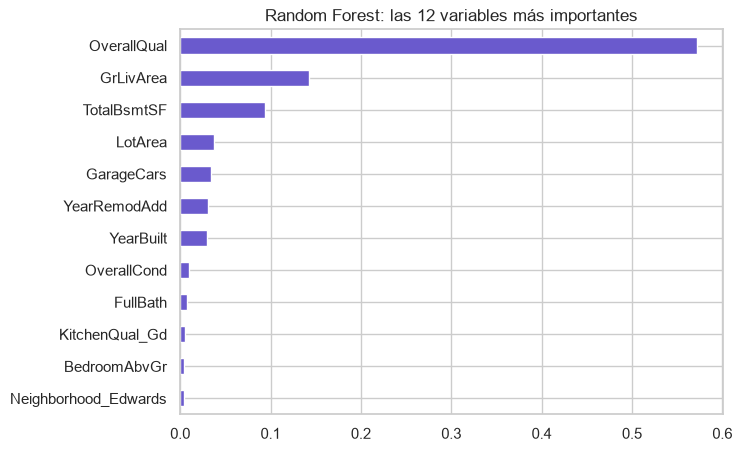

In [16]:
importancias = pd.Series(bosque.feature_importances_, index=Xtr.columns).sort_values(ascending=False)
ax = importancias.head(12).sort_values().plot(kind="barh", figsize=(7, 5), color="slateblue")
ax.set(title="Random Forest: las 12 variables más importantes")
plt.show()

Coincide con el EDA: **calidad general**, **área habitable** y **área del sótano** dominan. Cuando el modelo y el EDA cuentan la misma historia, ganamos confianza.

---
## 8. Análisis de errores: ¿en qué casas se equivoca más?

In [17]:
pred_va = np.expm1(LinearRegression().fit(Xtr, np.log1p(y_train)).predict(Xva))
errores = X_valid.assign(real=y_valid, predicho=pred_va)
errores["error_%"] = (errores["predicho"] / errores["real"] - 1) * 100
errores["rango_precio"] = pd.qcut(errores["real"], 4, labels=["barata", "media-baja", "media-alta", "cara"])

print(errores.groupby("rango_precio", observed=True)["error_%"].apply(lambda e: e.abs().mean()).round(1).to_frame("MAPE_%"))
errores.reindex(errores["error_%"].abs().sort_values(ascending=False).index).head(5)[
    ["Neighborhood", "OverallQual", "GrLivArea", "real", "predicho", "error_%"]
]

              MAPE_%
rango_precio        
barata         14.20
media-baja      9.70
media-alta      8.90
cara           11.20


,Neighborhood,OverallQual,GrLivArea,real,predicho,error_%
964,OldTown,3,968,37900,"79,211.30",109.00
708,BrkSide,3,729,52000,"88,876.56",70.92
587,ClearCr,5,1473,143000,"223,316.65",56.17
656,NAmes,6,1458,97500,"138,893.24",42.45
712,Sawyer,6,1479,130500,"185,353.68",42.03


Mirar los peores errores uno por uno suele revelar algo: casas atípicas, ventas especiales (`SaleCondition`) o datos raros. Es el insumo para la **siguiente iteración** de CRISP-DM.

---
## 9. Evaluación final en TEST

Elegimos el modelo **con validación** y lo evaluamos **una sola vez** en test. Tomamos *Gradient Boosting + log*: está entre los mejores MAPE de validación y fue el mejor en la validación cruzada.
(La lineal + log queda a menos de 1 punto: sería la elección si el negocio necesita **explicar** cada predicción.)

Lo reentrenamos con train + validación (más datos = mejor modelo).

In [18]:
final = HistGradientBoostingRegressor(random_state=config.SEMILLA)
final.fit(X_cv, np.log1p(y_cv))
pred_test = np.expm1(final.predict(Xte))
metricas_test = metricas_regresion(y_test, pred_test)
metricas_test

{'MAE': 17150.89, 'RMSE': 25594.5, 'MAPE_%': 10.19, 'R2': 0.8896}

In [19]:
dentro_15 = (np.abs(pred_test / y_test - 1) <= 0.15).mean()
print(f"MAPE en test: {metricas_test['MAPE_%']} %  → criterio < 15 %: {'CUMPLE' if metricas_test['MAPE_%'] < 15 else 'NO CUMPLE'}")
print(f"Casas con error ≤ 15 %: {dentro_15:.0%}  (criterio de negocio: 80 %)  → {'cumple' if dentro_15 >= 0.8 else 'no cumple'}")

MAPE en test: 10.19 %  → criterio < 15 %: CUMPLE
Casas con error ≤ 15 %: 82%  (criterio de negocio: 80 %)  → cumple


**Conclusión para el negocio:** un modelo con 14 variables estima el precio con un error típico de alrededor del 10 %, frente al 31 % de no tener modelo.
Hay que comunicar también **sus límites**: datos de 2006-2010, casas atípicas y barrios con pocas ventas.

---
## Ejercicios guiados (20 min)

1. **Más variables:** agrega `TotalSF`, `TotalBath` y `HouseAge` (creadas en el módulo 03) a las numéricas. ¿Mejora la regresión lineal con log?
2. **Sin los outliers:** elimina del **train** las casas con `GrLivArea > 4000` y reentrena la lineal con log. ¿Cambia el MAPE de validación?
3. **Random Forest regularizado:** prueba `max_depth` 8, 12 y 16 y `min_samples_leaf` 1, 3 y 5. ¿Puedes reducir la brecha sin empeorar la validación?
4. **Reflexión:** ¿por qué no deberíamos volver a ajustar el modelo después de ver el resultado en test?

Soluciones en `ejercicios/soluciones/solucion_02_modelos.py`.

In [20]:
# Tu código aquí